# Neural sentiment classifiers
## Dense network tuning
Select a Dense network using macro F1 on a stratified validation split. The model averages token embeddings before the hidden layer, so its predictions are insensitive to word order. The 200 test comments are reserved for final evaluation.

In [1]:
import sys
from pathlib import Path

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))

import numpy as np
from src.models import build_dense
from src.preprocessing import (
    MAX_LEN, SEED, build_vectorizer, load_splits, train_val_split,
    vectorize, vocabulary_size,
)
from src.train import BASE_GRID, grid_search, train_model
from src.visualize import plot_learning_curves

In [2]:
texts, labels, _, _ = load_splits()
texts_tr, texts_val, y_tr, y_val = train_val_split(texts, labels, seed=SEED)
vectorizer = build_vectorizer(texts_tr, max_len=MAX_LEN)
vocab_size = vocabulary_size(vectorizer)
X_tr = vectorize(vectorizer, texts_tr)
X_val = vectorize(vectorizer, texts_val)
assert X_tr.shape == (680, MAX_LEN) and X_val.shape == (120, MAX_LEN)
assert np.bincount(y_tr).tolist() == [340, 340]
assert np.bincount(y_val).tolist() == [60, 60]
print(f"Training: {len(y_tr)} | Validation: {len(y_val)} | Vocabulary: {vocab_size}")

Training: 680 | Validation: 120 | Vocabulary: 2138


### Grid and selection rule
Use the same split and seed for all 48 trials. Each trial restores the epoch with the lowest validation loss. Rank the restored models by validation macro F1 and break ties using validation loss. The table shows the five highest-ranked configurations.

In [3]:
dense_grid = grid_search(
    build_dense, BASE_GRID, X_tr, y_tr, X_val, y_val,
    vocab_size=vocab_size, epochs=30, seed=SEED,
)
assert len(dense_grid) == 48 and not dense_grid.duplicated(list(BASE_GRID)).any()
dense_grid.loc[:, [*BASE_GRID, "val_f1_macro", "val_accuracy", "best_val_loss", "best_epoch"]].head(5)

,embed_dim,units,dropout,lr,batch_size,val_f1_macro,val_accuracy,best_val_loss,best_epoch
0,32,32,0.5,0.003,32,0.758182,0.758333,0.554038,4
1,32,32,0.2,0.003,16,0.757913,0.758333,0.543800,2
2,32,32,0.2,0.003,32,0.749931,0.750000,0.540455,3
3,32,32,0.5,0.001,32,0.749722,0.750000,0.548143,8
4,32,32,0.5,0.001,16,0.749722,0.750000,0.550326,5


### Learning curves for the selected configuration
Repeat the winning trial with the same seed and plot training and validation loss and accuracy. The dotted line marks the epoch restored by early stopping.

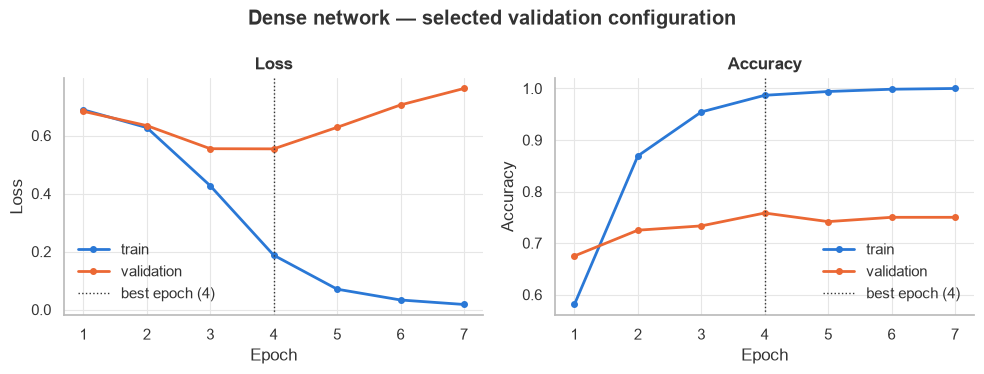

In [4]:
best = dense_grid.iloc[0]
dense_params = dict(
    vocab_size=vocab_size, max_len=MAX_LEN, embed_dim=int(best.embed_dim),
    units=int(best.units), dropout=float(best.dropout), lr=float(best.lr),
)
dense_history, _ = train_model(
    build_dense, dense_params, X_tr, y_tr, X_val, y_val,
    batch_size=int(best.batch_size), epochs=30, seed=SEED,
)
dense_fig = plot_learning_curves(
    dense_history, title="Dense network — selected validation configuration",
    name="03_dense_learning_curves",
)

In [5]:
hist = dense_history.history
epoch = int(np.argmin(hist["val_loss"]))
spread = best.val_f1_macro - dense_grid.iloc[4].val_f1_macro
print(f"Best validation macro F1: {best.val_f1_macro:.3f}. "
      f"Difference from fifth place: {spread:.3f}.")
print(f"At the refit's minimum validation loss (epoch {epoch + 1}), "
      f"training accuracy was {hist['accuracy'][epoch]:.1%} "
      f"and validation accuracy was {hist['val_accuracy'][epoch]:.1%}.")

Best validation macro F1: 0.758. Difference from fifth place: 0.008.
At the refit's minimum validation loss (epoch 4), training accuracy was 98.7% and validation accuracy was 75.8%.
